# StorSeismic Section 4: Field Data Workflow (Stratton 3D + SEG/EAGE 3-D Salt Model) — Pure Synthetic Stage 2A

Standalone adaptation of `nb3_3_stratton_segsalt.ipynb` evaluating **SEG/EAGE 3-D Salt Model (Synthetic)** + **Stratton 3D (3D Land Field Data)** **without** the 25% field-preservation mix during Stage 2A fine-tuning:
1. **Stage 1:** Self-supervised MLM pre-training (`BERT_MINI`, 15% masking with random + contiguous-gap spans, **50/50 SEG Salt + Stratton 3D mix**, inverse-energy weighting, best-checkpoint saving).
2. **Stage 2:** Supervised fine-tuning with partial layer freezing (`k=2`) for **Pure Synthetic Denoising** (`DENOISE_FIELD_MIX_RATIO = 0.0`, SEG Salt only + Gaussian noise) and **1D Velocity Prediction** (token-0 head with sigmoid output, cosine LR, and early stopping).
3. **Stage 3:** Inference, $f-k$ spectral decomposition, 2D velocity cross-section, $V_p$ parity scatter, zero-shot trace interpolation, and 16-head attention dissection.

### Key Configuration Changes (No-Mix Stage 2A Ablation)
- **`DENOISE_FIELD_MIX_RATIO = 0.0`:** Stage 2A trains strictly on SEG Salt synthetic gathers + additive Gaussian noise (0% Stratton 3D field mix), matching the original StorSeismic paper workflow.
- **Stage 1 Pre-Training Unchanged:** Retains the exact 50/50 SEG Salt + Stratton 3D mix, inverse-energy weighting, and contiguous-gap MLM augmentation.
- **Separate Output Directory (`./results/stratton_segsalt_nomix`):** Preserves your previous 25%-mix checkpoints and figures in `./results/stratton_segsalt/` for direct side-by-side comparison.

### Expected Data Paths
- `./data/Salt_Model_3D/3-D_Salt_Model/ClassicA/salt-a1.segy`
- `./data/Salt_Model_3D/3-D_Salt_Model/VEL_GRIDS/SALTF.ZIP`
- `./data/Stratton3D_32bit.sgy`

In [1]:
import os
import math
import json
import zipfile
import numpy as np
import segyio
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, resample
from scipy.interpolate import interp1d

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# Reproducibility & Device
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Paths (relative to storseismic/ directory)
SALT_SEGY_PATH = "./data/Salt_Model_3D/3-D_Salt_Model/ClassicA/salt-a1.segy"
SALT_VEL_ZIP_PATH = "./data/Salt_Model_3D/3-D_Salt_Model/VEL_GRIDS/SALTF.ZIP"
STRATTON_SEGY_PATH = "./data/Stratton3D_32bit.sgy"
SAVE_DIR = "./results/stratton_segsalt_nomix"
os.makedirs(SAVE_DIR, exist_ok=True)

# Hyperparameters (identical to nb3_1 BERT_MINI)
N_TRACES = 70
N_TIME = 256
HIDDEN_DIM = 256
NUM_LAYERS = 4
NUM_HEADS = 4
MASK_RATIO = 0.15
LR = 5e-4
MAX_GATHERS = 500  # Match nb3_1 500-gather scale (400 train / 100 test)
DENOISE_FIELD_MIX_RATIO = 0.0  # Pure synthetic SEG Salt fine-tuning in Stage 2A (0% Stratton 3D mix)

RUN_TRAINING = True  # Set True on first run to train & save; False to load saved checkpoints
PRETRAIN_EPOCHS = 300
FINETUNE_DENOISE_EPOCHS = 250
FINETUNE_VEL_EPOCHS = 250
HISTORY_PATH = os.path.join(SAVE_DIR, "training_history.npz")

Using device: cuda


## 1. Load & Preprocess SEG/EAGE 3-D Salt (Synthetic) + Stratton 3D (Land Field)

In [2]:
def normalize_gather(gather):
    """Per-gather peak-absolute normalization strictly to [-1, 1] (unified across synthetic & field)."""
    max_val = np.max(np.abs(gather)) + 1e-8
    return (gather / max_val).astype(np.float32)


def standardize_gather(gather):
    """Legacy standardization helper (unused to avoid amplitude-scale mismatch with SEG Salt)."""
    mean = np.mean(gather)
    std = np.std(gather) + 1e-8
    return ((gather - mean) / std).astype(np.float32)


def apply_time_gain_and_clip(gather, gain_power=1.5, clip_pct=99.5):
    """
    Apply gentle spherical-divergence time gain (t^gain_power) and percentile
    soft clipping before peak-abs normalization to [-1, 1]. This boosts deeper salt
    reflections relative to the high-amplitude direct arrival so SEG Salt energy is
    comparable to field gathers (Stratton 3D / Volve 3D).
    """
    t_axis = np.linspace(0.2, 1.0, gather.shape[1], dtype=np.float32)
    gained = gather * (t_axis ** gain_power)[None, :]
    clip_val = np.percentile(np.abs(gained), clip_pct) + 1e-8
    gained = np.clip(gained, -clip_val, clip_val)
    return normalize_gather(gained)


def load_seg_salt_data(segy_path, vel_zip_path, max_gathers=500, target_traces=70, target_time=256):
    """
    Load true shot gathers from SEG/EAGE 3-D Salt ClassicA (salt-a1.segy) by grouping
    traces by FieldRecord (fallback: SourceX/SourceY), uniformly subsampling each shot
    to target_traces=70 (eliminating broken shot boundaries), resampling time to 256,
    applying time-gain + soft clipping + peak-abs normalization to [-1, 1], and extracting
    corresponding 1D velocity profiles (70 depth points) from SALTF.ZIP (Saltf@@).
    """
    if not os.path.exists(segy_path) or not os.path.exists(vel_zip_path):
        raise FileNotFoundError(f"SEG Salt files not found. Expected: {segy_path} and {vel_zip_path}")

    with zipfile.ZipFile(vel_zip_path, "r") as zf:
        vel_grid = np.frombuffer(zf.read("Saltf@@"), dtype=">f4").reshape(210, 676, 676)

    gathers = []
    vels = []
    with segyio.open(segy_path, "r", ignore_geometry=True) as f:
        dt_us = f.bin[segyio.BinField.Interval]
        fs_raw = 1e6 / float(dt_us) if dt_us > 0 else 125.0
        raw_t = len(f.samples)

        # Group trace indices by FieldRecord (true shot ID)
        fldr = np.asarray(f.attributes(segyio.TraceField.FieldRecord)[:])
        unique_shots, first_idx, counts = np.unique(fldr, return_index=True, return_counts=True)
        valid_mask = counts >= 20

        # Fallback to (SourceX, SourceY) if FieldRecord is not populated
        if np.sum(valid_mask) < 10:
            sx_all = np.asarray(f.attributes(segyio.TraceField.SourceX)[:])
            sy_all = np.asarray(f.attributes(segyio.TraceField.SourceY)[:])
            shot_keys = sx_all.astype(np.int64) * 1000000 + sy_all.astype(np.int64)
            unique_shots, first_idx, counts = np.unique(shot_keys, return_index=True, return_counts=True)
            valid_mask = counts >= 20
            key_arr = shot_keys
        else:
            key_arr = fldr

        # Preserve spatial order of shots
        valid_order = np.argsort(first_idx[valid_mask])
        valid_shots = unique_shots[valid_mask][valid_order]

        if len(valid_shots) == 0:
            raise ValueError("No valid shot gathers (>=20 traces) found in SEG Salt SEG-Y.")

        # Evenly sample up to max_gathers shots across the 3D survey in spatial order
        cand_pos = (
            np.linspace(0, len(valid_shots) - 1, min(len(valid_shots), max_gathers * 2), dtype=int)
            if len(valid_shots) > max_gathers
            else np.arange(len(valid_shots))
        )
        cand_shots = valid_shots[np.unique(cand_pos)]

        for shot_id in cand_shots:
            if len(gathers) >= max_gathers:
                break
            tr_indices = np.where(key_arr == shot_id)[0]

            # Read source & receiver coordinates to eliminate 3D multi-line sawtooth jumps
            hdr0 = f.header[int(tr_indices[0])]
            sx = float(hdr0[segyio.TraceField.SourceX])
            sy = float(hdr0[segyio.TraceField.SourceY])

            gx = np.asarray([f.header[int(i)][segyio.TraceField.GroupX] for i in tr_indices], dtype=np.float32)
            gy = np.asarray([f.header[int(i)][segyio.TraceField.GroupY] for i in tr_indices], dtype=np.float32)
            offsets = np.hypot(gx - sx, gy - sy)

            # Sort traces monotonically by offset (removes 6-line sawtooth discontinuities)
            order = np.argsort(offsets)
            tr_sorted = tr_indices[order]
            sub_idx = tr_sorted[np.linspace(0, len(tr_sorted) - 1, target_traces, dtype=int)]

            raw_g = np.asarray([f.trace[int(i)] for i in sub_idx], dtype=np.float32)  # (70, T_raw)
            if np.max(np.abs(raw_g)) < 1e-8 or not np.all(np.isfinite(raw_g)):
                continue

            g_res = resample(raw_g, target_time, axis=1).astype(np.float32)
            # Slightly stronger clip (98.5) lifts SEG Salt RMS energy closer to Stratton 3D
            gathers.append(apply_time_gain_and_clip(g_res, gain_power=1.5, clip_pct=98.5))

            ix = int(np.clip(round(sx / 20.0), 0, 675))
            iy = int(np.clip(round(sy / 20.0), 0, 675))
            v_1d = vel_grid[::3, iy, ix].astype(np.float32)  # 210 // 3 = 70 depth points
            vels.append(v_1d)

    fs_res = fs_raw * (target_time / raw_t)
    print(f"Loaded {len(gathers)} true SEG Salt shot gathers (FieldRecord-grouped, time-gained; raw fs={fs_raw:.1f} Hz -> resampled fs={fs_res:.1f} Hz)")
    return np.array(gathers, dtype=np.float32), np.array(vels, dtype=np.float32)


def load_stratton_gathers(segy_path, max_gathers=500, target_traces=70, target_time=256):
    """
    Load Stratton 3D land SEG-Y using ignore_geometry=True, sample evenly across
    the 3D survey in spatial order (skipping dead/zero edge chunks), resample time
    axis to 256 samples, and apply unified per-gather peak normalization to [-1, 1].
    """
    if not os.path.exists(segy_path):
        raise FileNotFoundError(f"Stratton 3D SEG-Y file not found at: {segy_path}")

    gathers = []
    with segyio.open(segy_path, "r", ignore_geometry=True) as f:
        dt_us = f.bin[segyio.BinField.Interval]
        fs_raw = 1e6 / float(dt_us) if dt_us > 0 else 500.0
        total_chunks = f.tracecount // target_traces
        if total_chunks == 0:
            raise ValueError(f"Stratton 3D file has fewer than {target_traces} traces.")

        # Evenly sample across the 3D volume in spatial order so 80/20 split is clean & diverse
        cand_indices = (
            np.linspace(0, total_chunks - 1, min(total_chunks, max_gathers * 2), dtype=int)
            if total_chunks > max_gathers
            else np.arange(total_chunks)
        )
        cand_indices = np.unique(cand_indices)
        raw_t = len(f.samples)

        for g_idx in cand_indices:
            if len(gathers) >= max_gathers:
                break
            start = int(g_idx) * target_traces
            end = start + target_traces
            raw_g = np.asarray(f.trace.raw[start:end], dtype=np.float32)
            if np.max(np.abs(raw_g)) < 1e-8:
                continue  # skip dead/all-zero edge gather
            g_res = resample(raw_g, target_time, axis=1)
            gathers.append(normalize_gather(g_res))

    fs_res = fs_raw * (target_time / raw_t)
    print(f"Loaded {len(gathers)} Stratton 3D pseudo-gathers (raw fs={fs_raw:.1f} Hz -> resampled fs={fs_res:.1f} Hz)")
    return np.array(gathers, dtype=np.float32), fs_res


synth_gathers, synth_vels = load_seg_salt_data(SALT_SEGY_PATH, SALT_VEL_ZIP_PATH, MAX_GATHERS, N_TRACES, N_TIME)
field_gathers, FS_STRATTON = load_stratton_gathers(STRATTON_SEGY_PATH, MAX_GATHERS, N_TRACES, N_TIME)

VEL_MIN = float(synth_vels.min())
VEL_MAX = float(synth_vels.max())
synth_vels_norm = (synth_vels - VEL_MIN) / (VEL_MAX - VEL_MIN + 1e-8)

print(f"Field (Stratton 3D) shape : {field_gathers.shape} | Amp range: [{field_gathers.min():.3f}, {field_gathers.max():.3f}]")
print(f"Synth (SEG Salt) shape    : {synth_gathers.shape} | Amp range: [{synth_gathers.min():.3f}, {synth_gathers.max():.3f}]")
print(f"Synth Velocity shape      : {synth_vels.shape} | Range: [{VEL_MIN:.1f}, {VEL_MAX:.1f}] m/s")

Loaded 138 true SEG Salt shot gathers (FieldRecord-grouped, time-gained; raw fs=125.0 Hz -> resampled fs=51.2 Hz)
Loaded 500 Stratton 3D pseudo-gathers (raw fs=500.0 Hz -> resampled fs=85.3 Hz)
Field (Stratton 3D) shape : (500, 70, 256) | Amp range: [-1.000, 1.000]
Synth (SEG Salt) shape    : (138, 70, 256) | Amp range: [-1.000, 1.000]
Synth Velocity shape      : (138, 70) | Range: [1500.0, 4482.0] m/s


## 2. PyTorch Datasets & Augmentations

In [3]:
class PretrainDataset(Dataset):
    """
    Self-supervised MLM dataset mixing 50% Synthetic + 50% Field data.
    Augmentations: polarity reversal, spatial trace-order flip, slight time shift, and BERT-style 15% masking
    (70% random trace masking + 30% contiguous 3-6 trace gap + random traces during training).
    """
    def __init__(self, synth_data, field_data, mask_ratio=0.15, augment=True, gap_aug_prob=0.30):
        self.synth = synth_data
        self.field = field_data
        self.n_synth = len(synth_data)
        self.mask_ratio = mask_ratio
        self.augment = augment
        self.gap_aug_prob = gap_aug_prob

        # Inverse-energy weighting so sparse SEG Salt and dense Stratton 3D contribute equally to MSE
        synth_energy = float(np.mean(synth_data ** 2)) + 1e-8
        field_energy = float(np.mean(field_data ** 2)) + 1e-8
        self.synth_weight = float(np.clip(field_energy / synth_energy, 1.0, 4.0))

    def __len__(self):
        return 2 * self.n_synth  # Strict 50/50 domain balance per epoch

    def __getitem__(self, idx):
        if idx < self.n_synth:
            x = self.synth[idx].copy()
            weight = self.synth_weight
        else:
            f_idx = np.random.randint(0, len(self.field)) if self.augment else (idx - self.n_synth) % len(self.field)
            x = self.field[f_idx].copy()
            weight = 1.0

        if self.augment:
            if np.random.rand() < 0.5:
                x = -x
            if np.random.rand() < 0.5:
                x = x[::-1].copy()  # physically valid horizontal flip
            shift = np.random.randint(-5, 6)
            if shift != 0:
                x = np.roll(x, shift, axis=1)

        label = x.copy()
        n_traces = x.shape[0]
        n_mask = max(1, int(round(n_traces * self.mask_ratio)))

        # Mix standard random masking with contiguous gap masking to strengthen zero-shot gap interpolation
        if self.augment and np.random.rand() < self.gap_aug_prob:
            gap_len = np.random.randint(3, min(7, n_mask + 1))
            gap_start = np.random.randint(2, n_traces - gap_len - 2)
            gap_idx = np.arange(gap_start, gap_start + gap_len)
            remaining = n_mask - gap_len
            if remaining > 0:
                avail = np.setdiff1d(np.arange(n_traces), gap_idx)
                extra_idx = np.random.choice(avail, size=remaining, replace=False)
                mask_idx = np.concatenate([gap_idx, extra_idx])
            else:
                mask_idx = gap_idx
        else:
            mask_idx = np.random.choice(n_traces, size=n_mask, replace=False)

        mask = np.zeros(n_traces, dtype=np.float32)
        mask[mask_idx] = 1.0

        for m in mask_idx:
            p = np.random.rand()
            if p < 0.8:
                x[m] = np.random.normal(0.0, 0.3, size=x.shape[1]).astype(np.float32)
            elif p < 0.9:
                rand_trace = np.random.randint(0, n_traces)
                x[m] = label[rand_trace]
            # else 10%: keep original trace unchanged

        return (
            torch.tensor(x, dtype=torch.float32),
            torch.tensor(label, dtype=torch.float32),
            torch.tensor(mask, dtype=torch.float32),
            torch.tensor(weight, dtype=torch.float32),
        )


class DenoiseDataset(Dataset):
    """
    Supervised denoising dataset:
    - Primary: clean SEG Salt synthetic gathers + additive Gaussian noise (sigma in {0.10, 0.20}).
    - With field_mix_ratio=0.0 (default in this notebook), trains strictly on synthetic SEG Salt gathers.
    """
    def __init__(self, synth_data, field_data=None, augment=True, field_mix_ratio=0.0):
        self.synth = synth_data
        self.field = field_data
        self.augment = augment
        self.field_mix_ratio = field_mix_ratio if (field_data is not None and len(field_data) > 0) else 0.0
        self.n_field_extra = (
            int(round(len(synth_data) * self.field_mix_ratio / max(1.0 - self.field_mix_ratio, 1e-6)))
            if self.field_mix_ratio > 0 else 0
        )

    def __len__(self):
        return len(self.synth) + self.n_field_extra

    def __getitem__(self, idx):
        if idx < len(self.synth):
            clean = self.synth[idx].copy()
            sigma = np.random.choice([0.10, 0.20])
        else:
            f_idx = np.random.randint(0, len(self.field)) if self.augment else (idx - len(self.synth)) % len(self.field)
            clean = self.field[f_idx].copy()
            if self.augment and np.random.rand() < 0.5:
                clean = clean[::-1].copy()
            sigma = np.random.choice([0.05, 0.10, 0.15])

        if self.augment and np.random.rand() < 0.5:
            clean = -clean

        noise = np.random.normal(0.0, sigma, size=clean.shape).astype(np.float32)
        noisy = normalize_gather(clean + noise)
        return torch.tensor(noisy, dtype=torch.float32), torch.tensor(clean, dtype=torch.float32)


class VelocityDataset(Dataset):
    """Supervised 1D velocity prediction dataset (predicts Vp(z) from token 0, matching nb3_1 & Section 3.3)."""
    def __init__(self, synth_data, synth_vels_norm, augment=True):
        self.synth = synth_data
        self.vels = synth_vels_norm
        self.augment = augment

    def __len__(self):
        return len(self.synth)

    def __getitem__(self, idx):
        x = self.synth[idx].copy()
        y = self.vels[idx].copy()
        if self.augment and np.random.rand() < 0.5:
            x = -x
        return torch.tensor(x, dtype=torch.float32), torch.tensor(y, dtype=torch.float32)

## 3. StorSeismic (`BERT_MINI`) Architecture & Layer Freezing

In [4]:
class SinusoidalPositionalEncoding(nn.Module):
    """Equation (1) of StorSeismic paper."""
    def __init__(self, d_model, max_len=512):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1), :]


class StorSeismic(nn.Module):
    """
    StorSeismic BERT_MINI architecture (L=4, H=256, A=4, d_ff=1024, Pre-LN):
    Linear Projection -> Sinusoidal Positional Encoding -> L Transformer Encoder Layers -> Prediction Head.
    """
    def __init__(self, time_dim=256, hidden_dim=256, num_layers=4, num_heads=4, dropout=0.1, out_dim=None):
        super().__init__()
        self.embedding = nn.Linear(time_dim, hidden_dim)
        self.pos_enc = SinusoidalPositionalEncoding(hidden_dim)

        self.encoder_layers = nn.ModuleList([
            nn.TransformerEncoderLayer(
                d_model=hidden_dim,
                nhead=num_heads,
                dim_feedforward=hidden_dim * 4,
                dropout=dropout,
                activation="gelu",
                batch_first=True,
                norm_first=True,
            )
            for _ in range(num_layers)
        ])
        self.head = nn.Linear(hidden_dim, out_dim if out_dim is not None else time_dim)

    def forward(self, x):
        x = self.embedding(x)
        x = self.pos_enc(x)
        for layer in self.encoder_layers:
            x = layer(x)
        return self.head(x)

    def forward_with_attention(self, x, average_heads=True):
        """Returns (output, list_of_attention_maps) across all encoder layers."""
        h = self.pos_enc(self.embedding(x))
        attn_maps = []
        for layer in self.encoder_layers:
            h_norm = layer.norm1(h)
            attn_out, attn_weights = layer.self_attn(
                h_norm, h_norm, h_norm, need_weights=True, average_attn_weights=average_heads
            )
            attn_maps.append(attn_weights.detach().cpu().numpy())
            h = h + layer.dropout1(attn_out)
            h = h + layer._ff_block(layer.norm2(h))
        return self.head(h), attn_maps

    def freeze_initial_layers(self, num_freeze=2):
        """Section 6.3: Freeze embedding + first num_freeze encoder layers."""
        for p in self.parameters():
            p.requires_grad = True
        if num_freeze > 0:
            for p in self.embedding.parameters():
                p.requires_grad = False
            for i in range(min(num_freeze, len(self.encoder_layers))):
                for p in self.encoder_layers[i].parameters():
                    p.requires_grad = False
        trainable = sum(p.numel() for p in self.parameters() if p.requires_grad)
        total = sum(p.numel() for p in self.parameters())
        print(f"Frozen embedding + {num_freeze} encoder layers | Trainable params: {trainable:,} / {total:,} ({100*trainable/total:.1f}%)")


def load_or_require_checkpoint(model, ckpt_path):
    if not os.path.exists(ckpt_path):
        raise FileNotFoundError(
            f"Checkpoint not found at {ckpt_path}. Set RUN_TRAINING = True for the first run."
        )
    model.load_state_dict(torch.load(ckpt_path, map_location=device, weights_only=True))
    model.eval()
    print(f"Loaded saved weights from {ckpt_path} (training skipped).")

## 4. Stage 1: Self-Supervised Pre-Training (50% SEG Salt + 50% Stratton 3D)

In [5]:
# Stratton 3D: keep 80/20 spatial split
f_split = max(1, int(0.8 * len(field_gathers)))
if f_split >= len(field_gathers) and len(field_gathers) > 1:
    f_split = len(field_gathers) - 1
f_train, f_test = field_gathers[:f_split], field_gathers[f_split:]

# SEG Salt: stratified shuffled 80/20 split by salt presence (max Vp > 3500 m/s)
rng = np.random.RandomState(SEED)
has_salt = (synth_vels.max(axis=1) > 3500.0)
train_idx, test_idx = [], []
for flag in (True, False):
    grp = np.where(has_salt == flag)[0]
    rng.shuffle(grp)
    cut = int(0.8 * len(grp))
    train_idx.extend(grp[:cut])
    test_idx.extend(grp[cut:])

train_idx, test_idx = np.array(train_idx), np.array(test_idx)
s_train, s_test = synth_gathers[train_idx], synth_gathers[test_idx]
v_train, v_test = synth_vels_norm[train_idx], synth_vels_norm[test_idx]

print(f"Train split: synth={len(s_train)}, field={len(f_train)} | Test split: synth={len(s_test)}, field={len(f_test)}")

pretrain_train_loader = DataLoader(
    PretrainDataset(s_train, f_train, MASK_RATIO, augment=True, gap_aug_prob=0.30),
    batch_size=32, shuffle=True
)
pretrain_test_loader = DataLoader(
    PretrainDataset(s_test, f_test, MASK_RATIO, augment=False, gap_aug_prob=0.0),
    batch_size=32, shuffle=False
)

model_pretrain = StorSeismic(N_TIME, HIDDEN_DIM, NUM_LAYERS, NUM_HEADS).to(device)
optimizer = torch.optim.RAdam(model_pretrain.parameters(), lr=LR)

pretrain_ckpt = os.path.join(SAVE_DIR, "storseismic_pretrained_mixed.pt")
best_pt_epoch, best_pt_test_loss, best_pt_state = 0, float("inf"), None

if RUN_TRAINING:
    pt_train_losses, pt_test_losses = [], []
    print("=== Stage 1: Self-Supervised Pre-Training (50% SEG Salt + 50% Stratton 3D, Best Checkpoint) ===")
    for epoch in range(1, PRETRAIN_EPOCHS + 1):
        model_pretrain.train()
        tr_loss = 0.0
        for x, label, mask, w in pretrain_train_loader:
            x, label, mask, w = x.to(device), label.to(device), mask.to(device), w.to(device)
            optimizer.zero_grad()
            pred = model_pretrain(x)
            mask_exp = mask.unsqueeze(-1)
            per_sample_mse = ((pred - label) ** 2 * mask_exp).sum(dim=(1, 2)) / (mask_exp.sum(dim=(1, 2)) * N_TIME + 1e-8)
            loss = (per_sample_mse * w).mean()
            loss.backward()
            optimizer.step()
            tr_loss += loss.item() * len(x)
        tr_loss /= len(pretrain_train_loader.dataset)

        model_pretrain.eval()
        te_loss = 0.0
        with torch.no_grad():
            for x, label, mask, _ in pretrain_test_loader:
                x, label, mask = x.to(device), label.to(device), mask.to(device)
                pred = model_pretrain(x)
                mask_exp = mask.unsqueeze(-1)
                loss = ((pred - label) ** 2 * mask_exp).sum() / (mask_exp.sum() * N_TIME + 1e-8)
                te_loss += loss.item() * len(x)
        te_loss /= len(pretrain_test_loader.dataset)
        pt_train_losses.append(tr_loss)
        pt_test_losses.append(te_loss)

        # Save best checkpoint (lowest test masked MSE) to prevent overfitting
        if te_loss < best_pt_test_loss:
            best_pt_test_loss = te_loss
            best_pt_epoch = epoch
            best_pt_state = {k: v.detach().cpu().clone() for k, v in model_pretrain.state_dict().items()}

        if epoch % 25 == 0 or epoch == 1:
            print(
                f"Epoch {epoch:3d}/{PRETRAIN_EPOCHS} | Train Masked MSE: {tr_loss:.6f} | "
                f"Test Masked MSE: {te_loss:.6f} (Best: {best_pt_test_loss:.6f} @ Ep {best_pt_epoch})"
            )

    if best_pt_state is not None:
        torch.save(best_pt_state, pretrain_ckpt)
        model_pretrain.load_state_dict({k: v.to(device) for k, v in best_pt_state.items()})
    model_pretrain.eval()
    print(f"Loaded & kept best pre-trained weights (Epoch {best_pt_epoch}, Test MSE={best_pt_test_loss:.6f}) -> {pretrain_ckpt}")
else:
    load_or_require_checkpoint(model_pretrain, pretrain_ckpt)

Train split: synth=110, field=400 | Test split: synth=28, field=100
=== Stage 1: Self-Supervised Pre-Training (50% SEG Salt + 50% Stratton 3D, Best Checkpoint) ===
Epoch   1/300 | Train Masked MSE: 0.429239 | Test Masked MSE: 0.348804 (Best: 0.348804 @ Ep 1)
Epoch  25/300 | Train Masked MSE: 0.054392 | Test Masked MSE: 0.043884 (Best: 0.043884 @ Ep 25)
Epoch  50/300 | Train Masked MSE: 0.043172 | Test Masked MSE: 0.038096 (Best: 0.037521 @ Ep 48)
Epoch  75/300 | Train Masked MSE: 0.040133 | Test Masked MSE: 0.035388 (Best: 0.034687 @ Ep 70)
Epoch 100/300 | Train Masked MSE: 0.037987 | Test Masked MSE: 0.033586 (Best: 0.033586 @ Ep 100)
Epoch 125/300 | Train Masked MSE: 0.036333 | Test Masked MSE: 0.033298 (Best: 0.032764 @ Ep 115)
Epoch 150/300 | Train Masked MSE: 0.035763 | Test Masked MSE: 0.033078 (Best: 0.032530 @ Ep 131)
Epoch 175/300 | Train Masked MSE: 0.034809 | Test Masked MSE: 0.031809 (Best: 0.031809 @ Ep 175)
Epoch 200/300 | Train Masked MSE: 0.033703 | Test Masked MSE: 0.0

## 5. Stage 2A: Fine-Tuning for Denoising (Pure Synthetic SEG Salt, Freezing First 2 Layers)

In [6]:
# Pure synthetic Stage 2A training (100% SEG Salt + Gaussian noise, DENOISE_FIELD_MIX_RATIO = 0.0);
# validation strictly on SEG Salt s_test.
denoise_train_loader = DataLoader(
    DenoiseDataset(s_train, field_data=None, augment=True, field_mix_ratio=DENOISE_FIELD_MIX_RATIO),
    batch_size=16, shuffle=True
)
denoise_test_loader = DataLoader(
    DenoiseDataset(s_test, field_data=None, augment=False, field_mix_ratio=0.0),
    batch_size=16, shuffle=False
)

model_denoise = StorSeismic(N_TIME, HIDDEN_DIM, NUM_LAYERS, NUM_HEADS, out_dim=N_TIME).to(device)
denoise_ckpt = os.path.join(SAVE_DIR, "storseismic_finetuned_denoise.pt")
best_den_epoch, best_den_test_loss, best_den_state = 0, float("inf"), None

if RUN_TRAINING:
    pretrained_dict = torch.load(pretrain_ckpt, map_location=device, weights_only=True)
    pretrained_dict = {k: v for k, v in pretrained_dict.items() if not k.startswith("head.")}
    model_denoise.load_state_dict(pretrained_dict, strict=False)
    model_denoise.freeze_initial_layers(num_freeze=2)
    optimizer_den = torch.optim.RAdam(filter(lambda p: p.requires_grad, model_denoise.parameters()), lr=LR)
    criterion_den = nn.MSELoss()

    den_train_losses, den_test_losses = [], []
    print(f"=== Stage 2A: Fine-Tuning Denoising (Pure Synthetic SEG Salt, {int(DENOISE_FIELD_MIX_RATIO*100)}% Field Mix, Last 2 Layers) ===")
    for epoch in range(1, FINETUNE_DENOISE_EPOCHS + 1):
        model_denoise.train()
        tr_loss = 0.0
        for noisy, clean in denoise_train_loader:
            noisy, clean = noisy.to(device), clean.to(device)
            optimizer_den.zero_grad()
            loss = criterion_den(model_denoise(noisy), clean)
            loss.backward()
            optimizer_den.step()
            tr_loss += loss.item() * len(noisy)
        tr_loss /= len(denoise_train_loader.dataset)

        model_denoise.eval()
        te_loss = 0.0
        with torch.no_grad():
            for noisy, clean in denoise_test_loader:
                noisy, clean = noisy.to(device), clean.to(device)
                te_loss += criterion_den(model_denoise(noisy), clean).item() * len(noisy)
        te_loss /= len(denoise_test_loader.dataset)
        den_train_losses.append(tr_loss)
        den_test_losses.append(te_loss)

        if te_loss < best_den_test_loss:
            best_den_test_loss = te_loss
            best_den_epoch = epoch
            best_den_state = {k: v.detach().cpu().clone() for k, v in model_denoise.state_dict().items()}

        if epoch % 25 == 0 or epoch == 1:
            print(
                f"Epoch {epoch:3d}/{FINETUNE_DENOISE_EPOCHS} | Train MSE: {tr_loss:.6f} | "
                f"Test MSE: {te_loss:.6f} (Best: {best_den_test_loss:.6f} @ Ep {best_den_epoch})"
            )

    if best_den_state is not None:
        torch.save(best_den_state, denoise_ckpt)
        model_denoise.load_state_dict({k: v.to(device) for k, v in best_den_state.items()})
    model_denoise.eval()
    print(f"Loaded & kept best denoising weights (Epoch {best_den_epoch}, Test MSE={best_den_test_loss:.6f}) -> {denoise_ckpt}")
else:
    load_or_require_checkpoint(model_denoise, denoise_ckpt)

Frozen embedding + 2 encoder layers | Trainable params: 1,645,312 / 3,290,624 (50.0%)
=== Stage 2A: Fine-Tuning Denoising (Pure Synthetic SEG Salt, 0% Field Mix, Last 2 Layers) ===
Epoch   1/250 | Train MSE: 0.140875 | Test MSE: 0.133252 (Best: 0.133252 @ Ep 1)
Epoch  25/250 | Train MSE: 0.041516 | Test MSE: 0.038805 (Best: 0.038805 @ Ep 25)
Epoch  50/250 | Train MSE: 0.033569 | Test MSE: 0.029249 (Best: 0.029249 @ Ep 50)
Epoch  75/250 | Train MSE: 0.028843 | Test MSE: 0.024651 (Best: 0.024651 @ Ep 75)
Epoch 100/250 | Train MSE: 0.026288 | Test MSE: 0.022808 (Best: 0.021499 @ Ep 98)
Epoch 125/250 | Train MSE: 0.024307 | Test MSE: 0.020801 (Best: 0.019922 @ Ep 116)
Epoch 150/250 | Train MSE: 0.023589 | Test MSE: 0.019648 (Best: 0.019023 @ Ep 138)
Epoch 175/250 | Train MSE: 0.022365 | Test MSE: 0.017915 (Best: 0.017915 @ Ep 175)
Epoch 200/250 | Train MSE: 0.021925 | Test MSE: 0.017520 (Best: 0.017284 @ Ep 198)
Epoch 225/250 | Train MSE: 0.021105 | Test MSE: 0.017018 (Best: 0.017018 @ Ep 

## 6. Stage 2B: Fine-Tuning for 1D Velocity Prediction (Freezing First 2 Layers)

In [7]:
vel_dim = synth_vels.shape[1]  # 70 depth samples
vel_train_loader = DataLoader(VelocityDataset(s_train, v_train, True), batch_size=16, shuffle=True)
vel_test_loader = DataLoader(VelocityDataset(s_test, v_test, False), batch_size=16, shuffle=False)

model_vel = StorSeismic(N_TIME, HIDDEN_DIM, NUM_LAYERS, NUM_HEADS, out_dim=vel_dim).to(device)
vel_ckpt = os.path.join(SAVE_DIR, "storseismic_finetuned_velpred.pt")
best_vel_epoch, best_vel_test_loss, best_vel_state = 0, float("inf"), None
VEL_PATIENCE = 80

if RUN_TRAINING:
    pretrained_dict = torch.load(pretrain_ckpt, map_location=device, weights_only=True)
    pretrained_dict = {k: v for k, v in pretrained_dict.items() if not k.startswith("head.")}
    model_vel.load_state_dict(pretrained_dict, strict=False)

    model_vel.freeze_initial_layers(num_freeze=2)
    optimizer_vel = torch.optim.RAdam(
        filter(lambda p: p.requires_grad, model_vel.parameters()),
        lr=LR,
        weight_decay=1e-4,
    )
    scheduler_vel = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer_vel, T_max=FINETUNE_VEL_EPOCHS, eta_min=1e-5
    )
    criterion_vel = nn.L1Loss()

    vel_train_losses, vel_test_losses = [], []
    epochs_no_improve = 0
    print("=== Stage 2B: Fine-Tuning Velocity Prediction (SEG Salt Labels, Token-0 Head, Cosine LR + Early Stopping) ===")
    for epoch in range(1, FINETUNE_VEL_EPOCHS + 1):
        model_vel.train()
        tr_loss = 0.0
        for x, y in vel_train_loader:
            x, y = x.to(device), y.to(device)
            optimizer_vel.zero_grad()
            # Predict from first output token (zero-offset trace), matching nb3_1 & Section 3.3
            pred = torch.sigmoid(model_vel(x)[:, 0, :])
            loss = criterion_vel(pred, y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model_vel.parameters(), max_norm=1.0)
            optimizer_vel.step()
            tr_loss += loss.item() * len(x)
        tr_loss /= len(vel_train_loader.dataset)
        scheduler_vel.step()

        model_vel.eval()
        te_loss = 0.0
        with torch.no_grad():
            for x, y in vel_test_loader:
                x, y = x.to(device), y.to(device)
                pred = torch.sigmoid(model_vel(x)[:, 0, :])
                te_loss += criterion_vel(pred, y).item() * len(x)
        te_loss /= len(vel_test_loader.dataset)
        vel_train_losses.append(tr_loss)
        vel_test_losses.append(te_loss)

        if te_loss < best_vel_test_loss:
            best_vel_test_loss = te_loss
            best_vel_epoch = epoch
            epochs_no_improve = 0
            best_vel_state = {k: v.detach().cpu().clone() for k, v in model_vel.state_dict().items()}
        else:
            epochs_no_improve += 1

        if epoch % 25 == 0 or epoch == 1:
            mae_ms = te_loss * (VEL_MAX - VEL_MIN)
            best_mae_ms = best_vel_test_loss * (VEL_MAX - VEL_MIN)
            print(
                f"Epoch {epoch:3d}/{FINETUNE_VEL_EPOCHS} | Train L1: {tr_loss:.5f} | "
                f"Test L1: {te_loss:.5f} (~{mae_ms:.1f} m/s | Best: {best_mae_ms:.1f} m/s @ Ep {best_vel_epoch})"
            )

        if epochs_no_improve >= VEL_PATIENCE:
            print(f"Early stopping Stage 2B at Epoch {epoch} (no improvement for {VEL_PATIENCE} epochs; best @ Ep {best_vel_epoch}).")
            break

    if best_vel_state is not None:
        torch.save(best_vel_state, vel_ckpt)
        model_vel.load_state_dict({k: v.to(device) for k, v in best_vel_state.items()})
    model_vel.eval()
    print(f"Loaded & kept best velocity weights (Epoch {best_vel_epoch}, Test MAE={best_vel_test_loss*(VEL_MAX-VEL_MIN):.1f} m/s) -> {vel_ckpt}")

    np.savez(
        HISTORY_PATH,
        pt_train_losses=np.array(pt_train_losses, dtype=np.float32),
        pt_test_losses=np.array(pt_test_losses, dtype=np.float32),
        den_train_losses=np.array(den_train_losses, dtype=np.float32),
        den_test_losses=np.array(den_test_losses, dtype=np.float32),
        vel_train_losses=np.array(vel_train_losses, dtype=np.float32),
        vel_test_losses=np.array(vel_test_losses, dtype=np.float32),
        best_pt_epoch=np.array(best_pt_epoch, dtype=np.int32),
        best_den_epoch=np.array(best_den_epoch, dtype=np.int32),
        best_vel_epoch=np.array(best_vel_epoch, dtype=np.int32),
    )
    print(f"Saved training curves to {HISTORY_PATH}")
else:
    load_or_require_checkpoint(model_vel, vel_ckpt)
    if os.path.exists(HISTORY_PATH):
        hist = np.load(HISTORY_PATH)
        pt_train_losses = hist["pt_train_losses"].tolist()
        pt_test_losses = hist["pt_test_losses"].tolist()
        den_train_losses = hist["den_train_losses"].tolist()
        den_test_losses = hist["den_test_losses"].tolist()
        vel_train_losses = hist["vel_train_losses"].tolist()
        vel_test_losses = hist["vel_test_losses"].tolist()
        best_pt_epoch = int(hist["best_pt_epoch"]) if "best_pt_epoch" in hist else int(np.argmin(pt_test_losses) + 1)
        best_den_epoch = int(hist["best_den_epoch"]) if "best_den_epoch" in hist else int(np.argmin(den_test_losses) + 1)
        best_vel_epoch = int(hist["best_vel_epoch"]) if "best_vel_epoch" in hist else int(np.argmin(vel_test_losses) + 1)
        print(f"Loaded training curves from {HISTORY_PATH}")
    else:
        pt_train_losses = pt_test_losses = den_train_losses = den_test_losses = vel_train_losses = vel_test_losses = []

Frozen embedding + 2 encoder layers | Trainable params: 1,597,510 / 3,242,822 (49.3%)
=== Stage 2B: Fine-Tuning Velocity Prediction (SEG Salt Labels, Token-0 Head, Cosine LR + Early Stopping) ===
Epoch   1/250 | Train L1: 0.33109 | Test L1: 0.32425 (~966.9 m/s | Best: 966.9 m/s @ Ep 1)
Epoch  25/250 | Train L1: 0.12045 | Test L1: 0.11489 (~342.6 m/s | Best: 342.3 m/s @ Ep 22)
Epoch  50/250 | Train L1: 0.10600 | Test L1: 0.09965 (~297.2 m/s | Best: 292.6 m/s @ Ep 49)
Epoch  75/250 | Train L1: 0.07355 | Test L1: 0.07119 (~212.3 m/s | Best: 194.8 m/s @ Ep 74)
Epoch 100/250 | Train L1: 0.06857 | Test L1: 0.06548 (~195.3 m/s | Best: 181.7 m/s @ Ep 94)
Epoch 125/250 | Train L1: 0.05517 | Test L1: 0.06270 (~187.0 m/s | Best: 179.6 m/s @ Ep 113)
Epoch 150/250 | Train L1: 0.05525 | Test L1: 0.05962 (~177.8 m/s | Best: 164.3 m/s @ Ep 127)
Epoch 175/250 | Train L1: 0.04870 | Test L1: 0.05814 (~173.4 m/s | Best: 164.3 m/s @ Ep 127)
Epoch 200/250 | Train L1: 0.04673 | Test L1: 0.05653 (~168.6 m/s |

## 7. Stage 3: Inference, f-k Spectral Analysis, Zero-Shot Interpolation & Attention Diagnostics

Stratton 3D Field Denoising Diagnostics (N=100 unseen test gathers):
  Raw-Denoised Correlation (r) : 0.5775 +/- 0.0164
  Removed Energy (%)           : 67.91%


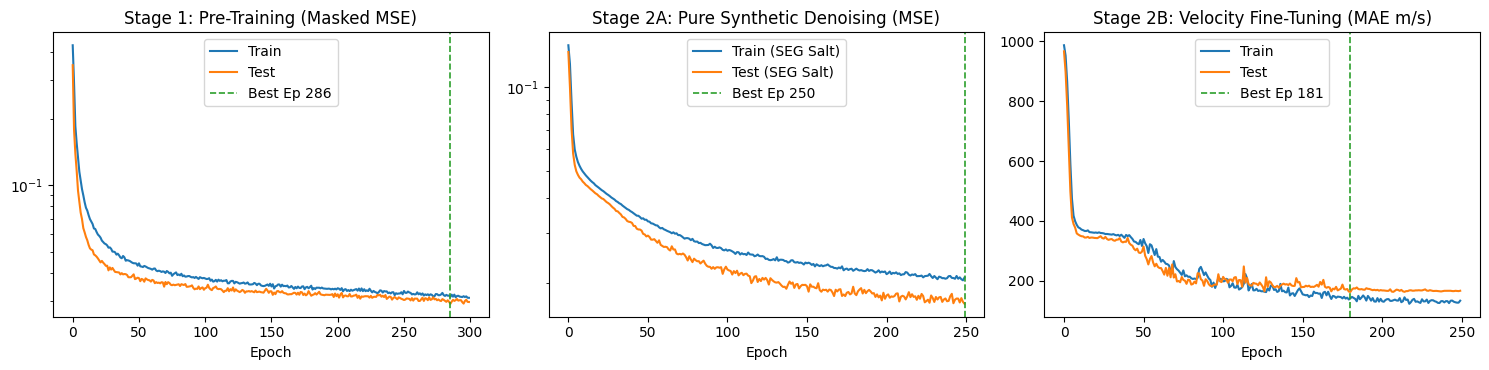

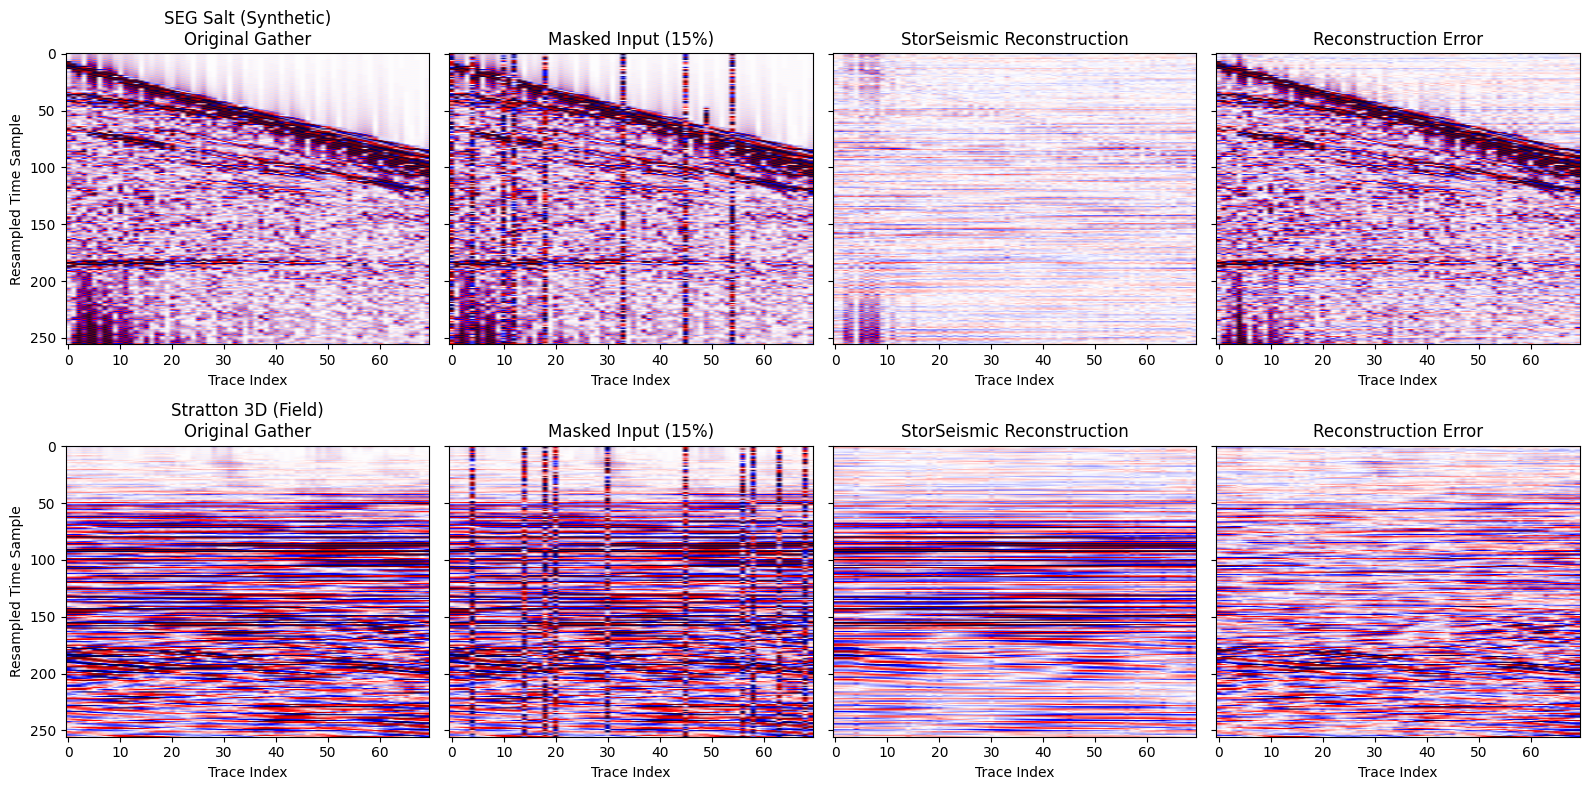

SEG Salt Denoise (sigma=0.15): Input SNR=4.65 dB -> Output SNR=4.46 dB


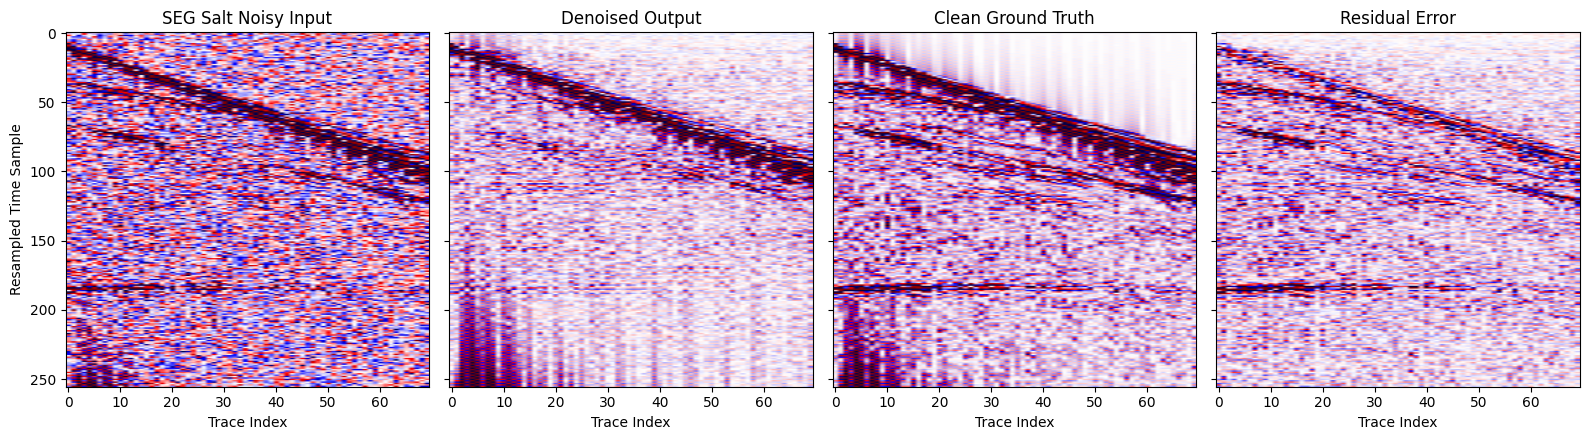

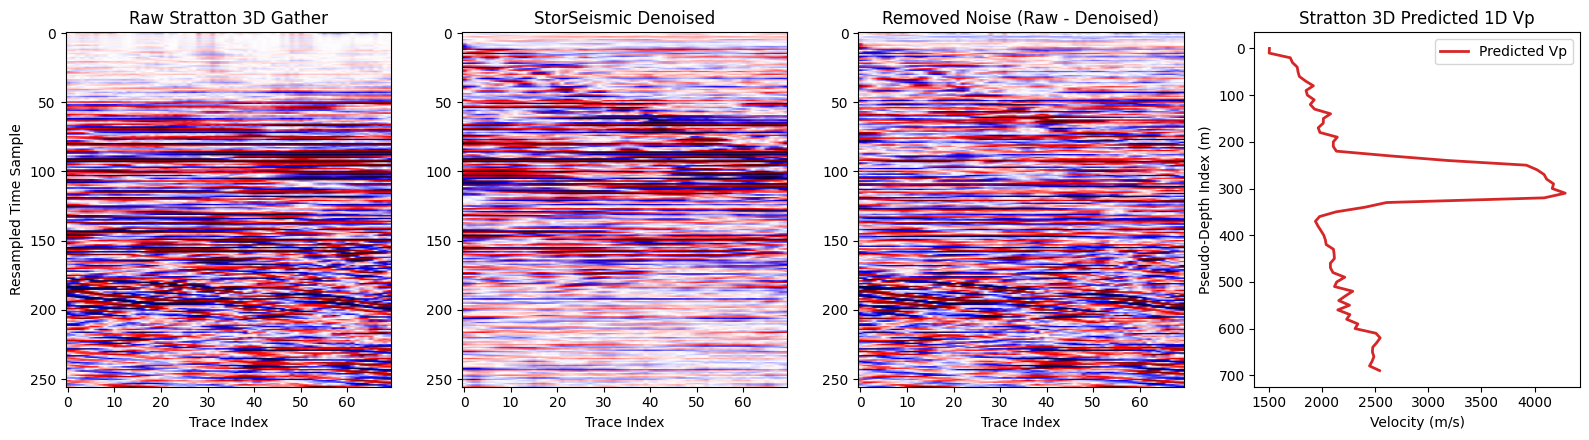

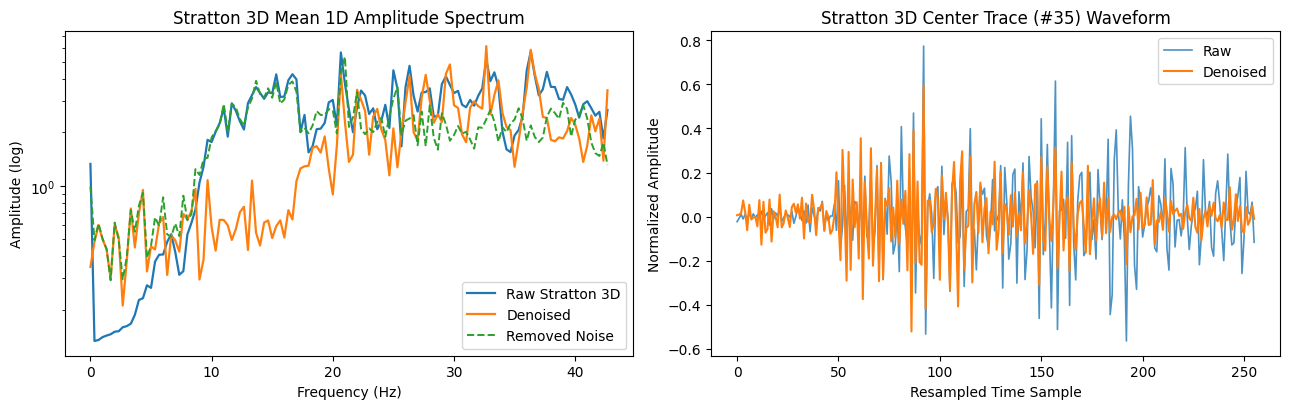

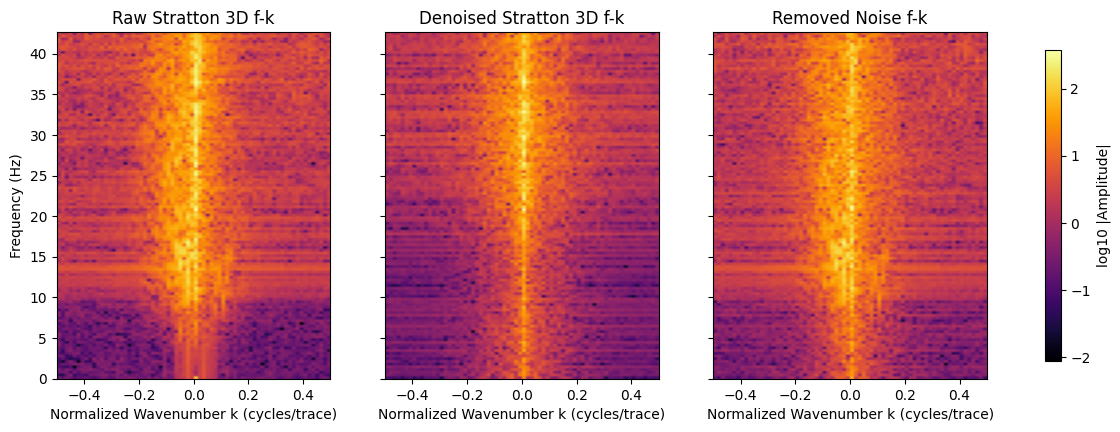

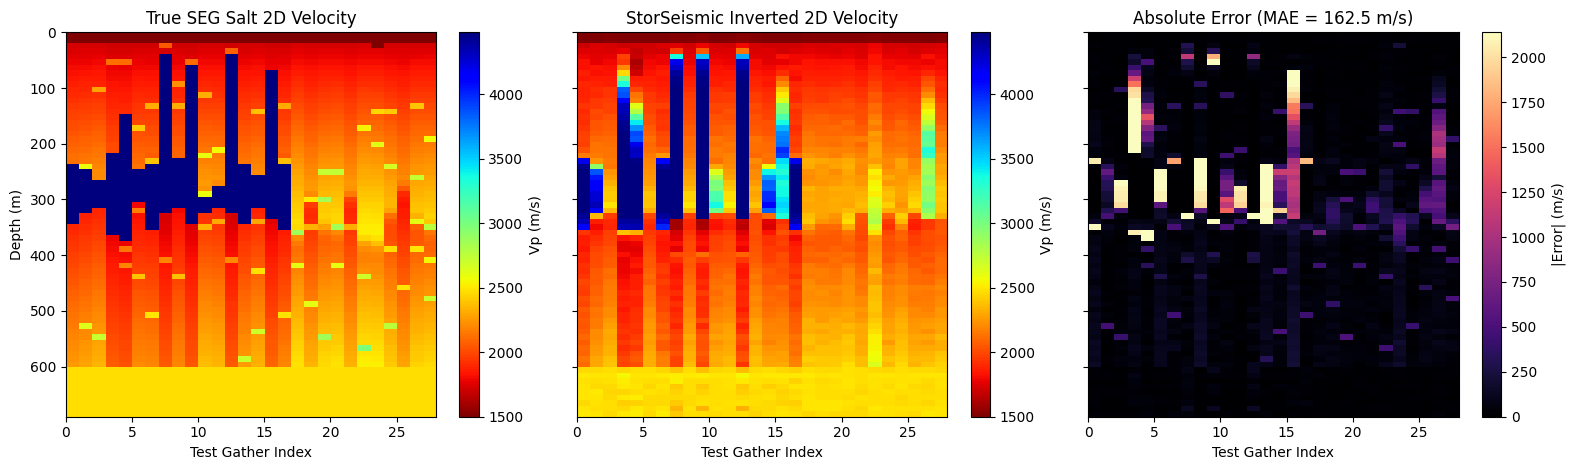

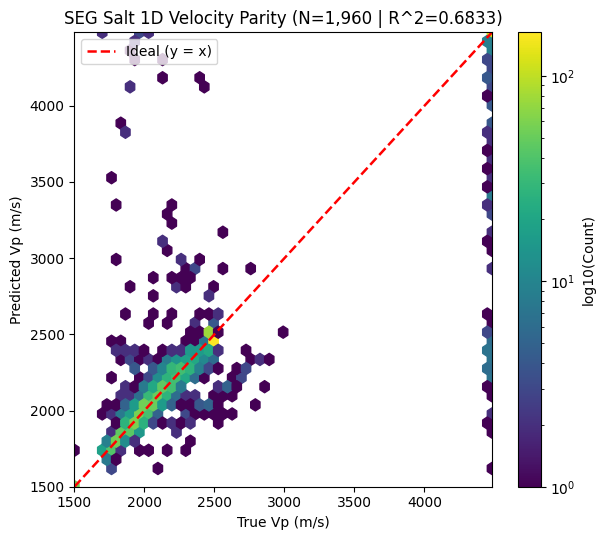

Zero-Shot Stratton 3D Interpolation SNR (dB) on Masked Traces:
  random20: Linear=14.74 | Cubic=15.53 | StorSeismic=2.85 dB
  gap5: Linear=7.76 | Cubic=9.62 | StorSeismic=2.17 dB


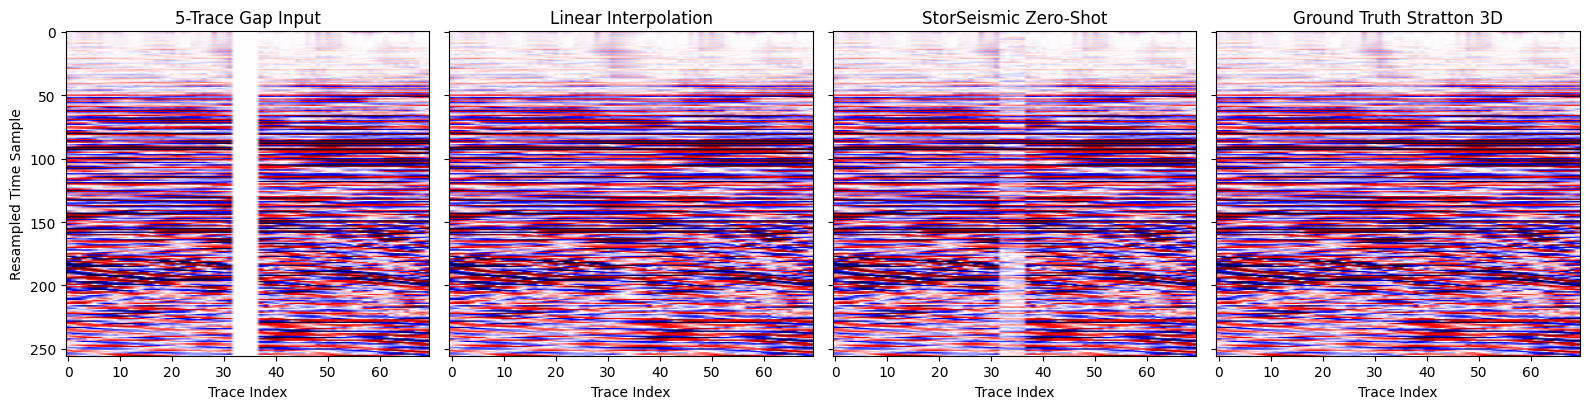

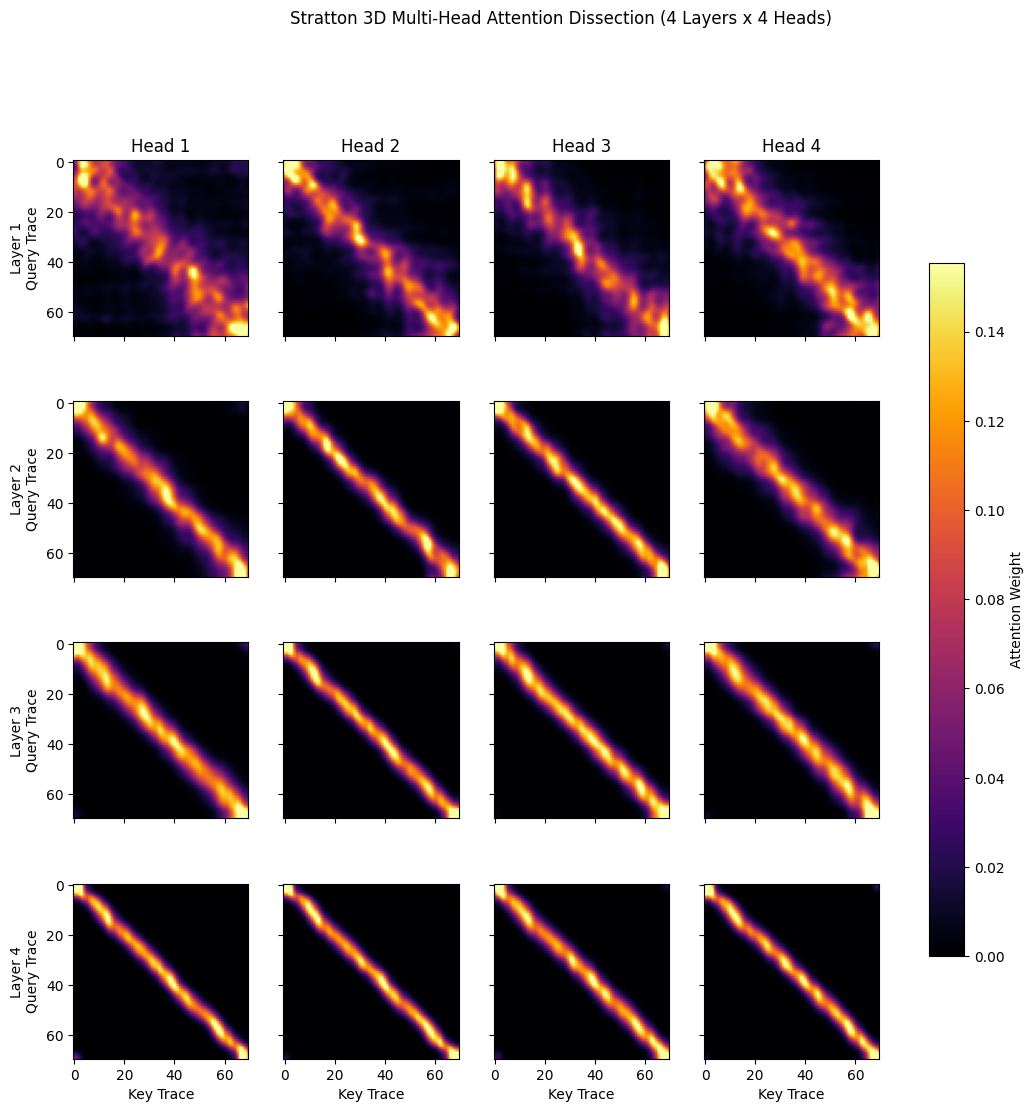

Saved bundle & config to ./results/stratton_segsalt_nomix
Test Metrics: Denoise MSE=0.017025 (SNR=4.46 dB) | Vel MAE=162.5 m/s (R^2=0.6833)


In [8]:
# ==============================================================================
# 1. INFERENCE ON UNSEEN STRATTON 3D TEST GATHER
# ==============================================================================
sample_idx = min(5, len(f_test) - 1)
field_shot = f_test[sample_idx]
field_tensor = torch.tensor(field_shot, dtype=torch.float32).unsqueeze(0).to(device)

model_pretrain.eval()
model_denoise.eval()
model_vel.eval()

with torch.no_grad():
    field_denoised = model_denoise(field_tensor).squeeze(0).cpu().numpy()
    field_vel_norm = torch.sigmoid(model_vel(field_tensor)[:, 0, :]).squeeze(0).cpu().numpy()

field_removed_noise = field_shot - field_denoised
field_vel_pred = field_vel_norm * (VEL_MAX - VEL_MIN) + VEL_MIN
vmin, vmax = -0.35, 0.35

# Reflection correlation & removed energy diagnostics on unseen Stratton 3D test set
field_corrs, field_rem_pcts = [], []
with torch.no_grad():
    for g in f_test:
        pred_g = model_denoise(torch.tensor(g[None], dtype=torch.float32, device=device)).squeeze(0).cpu().numpy()
        g_f, p_f = g.ravel(), pred_g.ravel()
        if np.std(g_f) > 1e-12 and np.std(p_f) > 1e-12:
            r = float(np.corrcoef(g_f, p_f)[0, 1])
        else:
            r = 0.0
        rem_pct = float(100.0 * np.sum((g - pred_g) ** 2) / (np.sum(g ** 2) + 1e-12))
        field_corrs.append(r)
        field_rem_pcts.append(rem_pct)

print(f"Stratton 3D Field Denoising Diagnostics (N={len(f_test)} unseen test gathers):")
print(f"  Raw-Denoised Correlation (r) : {np.mean(field_corrs):.4f} +/- {np.std(field_corrs):.4f}")
print(f"  Removed Energy (%)           : {np.mean(field_rem_pcts):.2f}%")

# ==============================================================================
# 2. TRAINING CURVES & PRE-TRAINING RECONSTRUCTION
# ==============================================================================
if len(pt_train_losses) > 0:
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
    axes[0].plot(pt_train_losses, label="Train")
    axes[0].plot(pt_test_losses, label="Test")
    if best_pt_epoch > 0:
        axes[0].axvline(best_pt_epoch - 1, color="tab:green", ls="--", lw=1.2, label=f"Best Ep {best_pt_epoch}")
    axes[0].set_title("Stage 1: Pre-Training (Masked MSE)")
    axes[0].set_xlabel("Epoch")
    axes[0].set_yscale("log")
    axes[0].legend()

    axes[1].plot(den_train_losses, label="Train (SEG Salt)")
    axes[1].plot(den_test_losses, label="Test (SEG Salt)")
    if best_den_epoch > 0:
        axes[1].axvline(best_den_epoch - 1, color="tab:green", ls="--", lw=1.2, label=f"Best Ep {best_den_epoch}")
    axes[1].set_title("Stage 2A: Pure Synthetic Denoising (MSE)")
    axes[1].set_xlabel("Epoch")
    axes[1].set_yscale("log")
    axes[1].legend()

    axes[2].plot([l * (VEL_MAX - VEL_MIN) for l in vel_train_losses], label="Train")
    axes[2].plot([l * (VEL_MAX - VEL_MIN) for l in vel_test_losses], label="Test")
    if best_vel_epoch > 0:
        axes[2].axvline(best_vel_epoch - 1, color="tab:green", ls="--", lw=1.2, label=f"Best Ep {best_vel_epoch}")
    axes[2].set_title("Stage 2B: Velocity Fine-Tuning (MAE m/s)")
    axes[2].set_xlabel("Epoch")
    axes[2].legend()

    plt.tight_layout()
    plt.savefig(os.path.join(SAVE_DIR, "report_1_training_curves.png"), dpi=300)
    plt.show()

# Pre-Training Masked Trace Reconstruction
np.random.seed(SEED)
pt_eval_ds = PretrainDataset(s_test, f_test, MASK_RATIO, augment=False, gap_aug_prob=0.0)
fig, axes = plt.subplots(2, 4, figsize=(16, 8), sharey=True)
s_idx_eval = min(sample_idx, len(s_test) - 1)
f_idx_eval = len(s_test) + min(sample_idx, len(f_test) - 1)

for row, (idx, name) in enumerate([(s_idx_eval, "SEG Salt (Synthetic)"), (f_idx_eval, "Stratton 3D (Field)")]):
    x_m, lbl_m, msk, _ = pt_eval_ds[idx]
    with torch.no_grad():
        rec_m = model_pretrain(x_m.unsqueeze(0).to(device)).squeeze(0).cpu().numpy()
    orig_m = lbl_m.numpy()
    masked_in = x_m.numpy()
    err_m = orig_m - rec_m

    for col, (img, ttl) in enumerate([
        (orig_m.T, f"{name}\nOriginal Gather"),
        (masked_in.T, "Masked Input (15%)"),
        (rec_m.T, "StorSeismic Reconstruction"),
        (err_m.T, "Reconstruction Error"),
    ]):
        axes[row, col].imshow(img, aspect="auto", cmap="seismic", vmin=vmin, vmax=vmax)
        axes[row, col].set_title(ttl)
        axes[row, col].set_xlabel("Trace Index")
    axes[row, 0].set_ylabel("Resampled Time Sample")

plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "report_2_pretrain_reconstruction.png"), dpi=300)
plt.show()

# ==============================================================================
# 3. SYNTHETIC DENOISING & VELOCITY PREDICTIONS
# ==============================================================================
np.random.seed(SEED)
all_noisy_s, all_clean_s = [], []
for clean_g in s_test:
    noise = np.random.normal(0.0, 0.15, size=clean_g.shape).astype(np.float32)
    all_noisy_s.append(normalize_gather(clean_g + noise))
    all_clean_s.append(clean_g)
all_noisy_s = np.array(all_noisy_s, dtype=np.float32)
all_clean_s = np.array(all_clean_s, dtype=np.float32)

with torch.no_grad():
    frozen_den_synth_preds = model_denoise(torch.tensor(all_noisy_s, device=device)).cpu().numpy()
    frozen_den_field_preds = model_denoise(torch.tensor(f_test, dtype=torch.float32, device=device)).cpu().numpy()
    frozen_vel_synth_preds = torch.sigmoid(model_vel(torch.tensor(s_test, dtype=torch.float32, device=device))[:, 0, :]).cpu().numpy() * (VEL_MAX - VEL_MIN) + VEL_MIN
    frozen_vel_field_preds = torch.sigmoid(model_vel(torch.tensor(f_test, dtype=torch.float32, device=device))[:, 0, :]).cpu().numpy() * (VEL_MAX - VEL_MIN) + VEL_MIN

v_test_ms = v_test * (VEL_MAX - VEL_MIN) + VEL_MIN
frozen_den_mse = float(np.mean((frozen_den_synth_preds - all_clean_s) ** 2))
frozen_vel_mae = float(np.mean(np.abs(frozen_vel_synth_preds - v_test_ms)))

def compute_snr_db(clean, est):
    sig_pow = np.sum(clean ** 2)
    noise_pow = np.sum((clean - est) ** 2) + 1e-12
    return float(10.0 * np.log10((sig_pow + 1e-12) / noise_pow))

snr_in_list = [compute_snr_db(c, n) for c, n in zip(all_clean_s, all_noisy_s)]
snr_out_list = [compute_snr_db(c, p) for c, p in zip(all_clean_s, frozen_den_synth_preds)]
print(f"SEG Salt Denoise (sigma=0.15): Input SNR={np.mean(snr_in_list):.2f} dB -> Output SNR={np.mean(snr_out_list):.2f} dB")

fig, axes = plt.subplots(1, 4, figsize=(16, 4.5), sharey=True)
for ax, img, ttl in [
    (axes[0], all_noisy_s[s_idx_eval].T, "SEG Salt Noisy Input"),
    (axes[1], frozen_den_synth_preds[s_idx_eval].T, "Denoised Output"),
    (axes[2], all_clean_s[s_idx_eval].T, "Clean Ground Truth"),
    (axes[3], (all_clean_s[s_idx_eval] - frozen_den_synth_preds[s_idx_eval]).T, "Residual Error"),
]:
    ax.imshow(img, aspect="auto", cmap="seismic", vmin=vmin, vmax=vmax)
    ax.set_title(ttl)
    ax.set_xlabel("Trace Index")
axes[0].set_ylabel("Resampled Time Sample")
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "report_3_synth_denoise.png"), dpi=300)
plt.show()

# ==============================================================================
# 4. UNSEEN FIELD DATA INFERENCE & SPECTRUM
# ==============================================================================
fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, img, ttl in [
    (axes[0], field_shot.T, "Raw Stratton 3D Gather"),
    (axes[1], field_denoised.T, "StorSeismic Denoised"),
    (axes[2], field_removed_noise.T, "Removed Noise (Raw - Denoised)"),
]:
    ax.imshow(img, aspect="auto", cmap="seismic", vmin=vmin, vmax=vmax)
    ax.set_title(ttl)
    ax.set_xlabel("Trace Index")
axes[0].set_ylabel("Resampled Time Sample")

depth_axis = np.arange(vel_dim) * 10.0
axes[3].plot(field_vel_pred, depth_axis, color="tab:red", lw=2.0, label="Predicted Vp")
axes[3].invert_yaxis()
axes[3].set_title("Stratton 3D Predicted 1D Vp")
axes[3].set_xlabel("Velocity (m/s)")
axes[3].set_ylabel("Pseudo-Depth Index (m)")
axes[3].legend()
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "report_4_field_inference.png"), dpi=300)
plt.show()

# 1D Amplitude Spectrum + Center Trace Waveform
fs_field = float(FS_STRATTON)
freqs = np.fft.rfftfreq(N_TIME, d=1.0 / fs_field)
raw_spec = np.mean(np.abs(np.fft.rfft(field_shot, axis=1)), axis=0)
den_spec = np.mean(np.abs(np.fft.rfft(field_denoised, axis=1)), axis=0)
rem_spec = np.mean(np.abs(np.fft.rfft(field_removed_noise, axis=1)), axis=0)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].semilogy(freqs, raw_spec + 1e-4, label="Raw Stratton 3D", lw=1.6)
axes[0].semilogy(freqs, den_spec + 1e-4, label="Denoised", lw=1.6)
axes[0].semilogy(freqs, rem_spec + 1e-4, label="Removed Noise", lw=1.4, linestyle="--")
axes[0].set_title("Stratton 3D Mean 1D Amplitude Spectrum")
axes[0].set_xlabel("Frequency (Hz)")
axes[0].set_ylabel("Amplitude (log)")
axes[0].legend()

center_tr = 35
axes[1].plot(field_shot[center_tr], label="Raw", lw=1.2, alpha=0.8)
axes[1].plot(field_denoised[center_tr], label="Denoised", lw=1.5)
axes[1].set_title("Stratton 3D Center Trace (#35) Waveform")
axes[1].set_xlabel("Resampled Time Sample")
axes[1].set_ylabel("Normalized Amplitude")
axes[1].legend()
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "report_5_field_spectrum_waveform.png"), dpi=300)
plt.show()

# ==============================================================================
# 5. f-k SPECTRUM DECOMPOSITION, 2D VELOCITY CROSS-SECTION & PARITY SCATTER
# ==============================================================================
f_nyq = fs_field / 2.0
k_nyq = 0.5
fk_raw = np.abs(np.fft.fftshift(np.fft.fft2(field_shot.T)))
fk_den = np.abs(np.fft.fftshift(np.fft.fft2(field_denoised.T)))
fk_res = np.abs(np.fft.fftshift(np.fft.fft2(field_removed_noise.T)))

mid_f = fk_raw.shape[0] // 2
fk_raw_pos = np.log10(fk_raw[mid_f:, :] + 1e-4)
fk_den_pos = np.log10(fk_den[mid_f:, :] + 1e-4)
fk_res_pos = np.log10(fk_res[mid_f:, :] + 1e-4)
fk_vmin = min(fk_raw_pos.min(), fk_den_pos.min(), fk_res_pos.min())
fk_vmax = max(fk_raw_pos.max(), fk_den_pos.max(), fk_res_pos.max())

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, (spec, ttl) in zip(axes, [
    (fk_raw_pos, "Raw Stratton 3D f-k"),
    (fk_den_pos, "Denoised Stratton 3D f-k"),
    (fk_res_pos, "Removed Noise f-k"),
]):
    im = ax.imshow(spec, aspect="auto", origin="lower", cmap="inferno",
                   extent=[-k_nyq, k_nyq, 0, f_nyq], vmin=fk_vmin, vmax=fk_vmax)
    ax.set_title(ttl)
    ax.set_xlabel("Normalized Wavenumber k (cycles/trace)")
axes[0].set_ylabel("Frequency (Hz)")
fig.colorbar(im, ax=axes.ravel().tolist(), label="log10 |Amplitude|", shrink=0.9)
plt.savefig(os.path.join(SAVE_DIR, "report_6_fk_spectrum_field.png"), dpi=300, bbox_inches="tight")
plt.show()

# 2D Multi-Gather Inverted Velocity Cross-Section
vel_abs_err = np.abs(frozen_vel_synth_preds - v_test_ms)
depth_m = np.arange(vel_dim) * 10.0

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
im0 = axes[0].imshow(v_test_ms.T, aspect="auto", cmap="jet_r",
                     extent=[0, len(v_test_ms), depth_m[-1], depth_m[0]], vmin=VEL_MIN, vmax=VEL_MAX)
axes[0].set_title("True SEG Salt 2D Velocity")
axes[0].set_xlabel("Test Gather Index")
axes[0].set_ylabel("Depth (m)")
fig.colorbar(im0, ax=axes[0], label="Vp (m/s)")

im1 = axes[1].imshow(frozen_vel_synth_preds.T, aspect="auto", cmap="jet_r",
                     extent=[0, len(v_test_ms), depth_m[-1], depth_m[0]], vmin=VEL_MIN, vmax=VEL_MAX)
axes[1].set_title("StorSeismic Inverted 2D Velocity")
axes[1].set_xlabel("Test Gather Index")
fig.colorbar(im1, ax=axes[1], label="Vp (m/s)")

im2 = axes[2].imshow(vel_abs_err.T, aspect="auto", cmap="magma",
                     extent=[0, len(v_test_ms), depth_m[-1], depth_m[0]], vmin=0, vmax=np.percentile(vel_abs_err, 98))
axes[2].set_title(f"Absolute Error (MAE = {frozen_vel_mae:.1f} m/s)")
axes[2].set_xlabel("Test Gather Index")
fig.colorbar(im2, ax=axes[2], label="|Error| (m/s)")
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "report_7_2d_velocity_cross_section.png"), dpi=300, bbox_inches="tight")
plt.show()

# Velocity Parity Density Scatter
y_true_flat = v_test_ms.ravel()
y_pred_flat = frozen_vel_synth_preds.ravel()
vel_r2 = float(1.0 - np.sum((y_true_flat - y_pred_flat) ** 2) / (np.sum((y_true_flat - np.mean(y_true_flat)) ** 2) + 1e-12))

fig, ax = plt.subplots(figsize=(6.2, 5.5))
hb = ax.hexbin(y_true_flat, y_pred_flat, gridsize=45, cmap="viridis", mincnt=1, bins="log")
lims = [min(y_true_flat.min(), y_pred_flat.min()), max(y_true_flat.max(), y_pred_flat.max())]
ax.plot(lims, lims, "r--", lw=1.8, label="Ideal (y = x)")
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel("True Vp (m/s)")
ax.set_ylabel("Predicted Vp (m/s)")
ax.set_title(f"SEG Salt 1D Velocity Parity (N={len(y_true_flat):,} | R^2={vel_r2:.4f})")
ax.legend(loc="upper left")
fig.colorbar(hb, ax=ax, label="log10(Count)")
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "report_8_velocity_parity_scatter.png"), dpi=300, bbox_inches="tight")
plt.show()

# ==============================================================================
# 6. ZERO-SHOT DEAD-TRACE INTERPOLATION (EXP B2 PROTOCOL)
# ==============================================================================
def classical_interp(gather_2d, mask_bool, kind="linear"):
    x_all = np.arange(gather_2d.shape[0])
    x_obs = x_all[~mask_bool]
    y_obs = gather_2d[~mask_bool]
    fn = interp1d(x_obs, y_obs, kind=kind, axis=0, bounds_error=False, fill_value="extrapolate")
    out = gather_2d.copy()
    out[mask_bool] = fn(x_all[mask_bool])
    return out

def zeroshot_interp(model, gather_2d, mask_bool, seed=42, n_avg=5):
    """Zero-shot MLM trace interpolation averaged over n_avg Gaussian mask draws to reduce variance."""
    rng_i = np.random.default_rng(seed)
    preds = []
    with torch.no_grad():
        for _ in range(n_avg):
            x_in = gather_2d.copy()
            x_in[mask_bool] = rng_i.normal(0.0, 0.3, size=(int(mask_bool.sum()), gather_2d.shape[1])).astype(np.float32)
            pred = model(torch.tensor(x_in[None], dtype=torch.float32, device=device)).cpu().numpy()[0]
            preds.append(pred[mask_bool])
    out = gather_2d.copy()
    out[mask_bool] = np.mean(preds, axis=0)
    return out

rng_b2 = np.random.default_rng(2025)
b2_results = {"random20": {"linear": [], "cubic": [], "storseismic": []},
              "gap5": {"linear": [], "cubic": [], "storseismic": []}}

for idx_g, g in enumerate(f_test):
    m_rand = np.zeros(N_TRACES, dtype=bool)
    m_rand[rng_b2.choice(np.arange(1, N_TRACES - 1), size=int(0.2 * N_TRACES), replace=False)] = True
    m_gap = np.zeros(N_TRACES, dtype=bool)
    m_gap[32:37] = True
    for name_s, m_s in [("random20", m_rand), ("gap5", m_gap)]:
        for m_name, pred_g in [
            ("linear", classical_interp(g, m_s, "linear")),
            ("cubic", classical_interp(g, m_s, "cubic")),
            ("storseismic", zeroshot_interp(model_pretrain, g, m_s, seed=100 + idx_g)),
        ]:
            b2_results[name_s][m_name].append(compute_snr_db(g[m_s], pred_g[m_s]))

print("Zero-Shot Stratton 3D Interpolation SNR (dB) on Masked Traces:")
for name_s in ["random20", "gap5"]:
    print(f"  {name_s}: Linear={np.mean(b2_results[name_s]['linear']):.2f} | "
          f"Cubic={np.mean(b2_results[name_s]['cubic']):.2f} | "
          f"StorSeismic={np.mean(b2_results[name_s]['storseismic']):.2f} dB")

m_gap_vis = np.zeros(N_TRACES, dtype=bool); m_gap_vis[32:37] = True
vis_lin = classical_interp(field_shot, m_gap_vis, "linear")
vis_ss = zeroshot_interp(model_pretrain, field_shot, m_gap_vis, seed=42)

fig, axes = plt.subplots(1, 4, figsize=(16, 4.2), sharey=True)
g_in = field_shot.copy(); g_in[m_gap_vis] = 0.0
for ax, img, ttl in [
    (axes[0], g_in.T, "5-Trace Gap Input"),
    (axes[1], vis_lin.T, "Linear Interpolation"),
    (axes[2], vis_ss.T, "StorSeismic Zero-Shot"),
    (axes[3], field_shot.T, "Ground Truth Stratton 3D"),
]:
    ax.imshow(img, aspect="auto", cmap="seismic", vmin=vmin, vmax=vmax)
    ax.set_title(ttl)
    ax.set_xlabel("Trace Index")
axes[0].set_ylabel("Resampled Time Sample")
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "report_9_zeroshot_interpolation.png"), dpi=300)
plt.show()

# ==============================================================================
# 7. SELF-ATTENTION MAP VISUALIZATION (4x4 MULTI-HEAD GRID)
# ==============================================================================
with torch.no_grad():
    _, attn_heads = model_pretrain.forward_with_attention(field_tensor, average_heads=False)

fig, axes = plt.subplots(NUM_LAYERS, NUM_HEADS, figsize=(13, 12), sharex=True, sharey=True)
for l_idx in range(NUM_LAYERS):
    for h_idx in range(NUM_HEADS):
        ax = axes[l_idx, h_idx]
        amap = attn_heads[l_idx][0, h_idx]
        im = ax.imshow(amap, cmap="inferno", vmin=0, vmax=np.percentile(amap, 99))
        if l_idx == 0:
            ax.set_title(f"Head {h_idx + 1}")
        if h_idx == 0:
            ax.set_ylabel(f"Layer {l_idx + 1}\nQuery Trace")
        if l_idx == NUM_LAYERS - 1:
            ax.set_xlabel("Key Trace")

fig.suptitle("Stratton 3D Multi-Head Attention Dissection (4 Layers x 4 Heads)", y=0.995)
fig.colorbar(im, ax=axes.ravel().tolist(), label="Attention Weight", shrink=0.75)
plt.savefig(os.path.join(SAVE_DIR, "report_10_multihead_attention.png"), dpi=300, bbox_inches="tight")
plt.show()

# Save evaluation bundle & config
bundle_path = os.path.join(SAVE_DIR, "ablation_frozen_bundle.npz")
np.savez_compressed(
    bundle_path,
    s_train=s_train, s_test=s_test, f_train=f_train, f_test=f_test,
    v_train=v_train, v_test=v_test,
    frozen_den_synth_preds=frozen_den_synth_preds,
    frozen_den_field_preds=frozen_den_field_preds,
    frozen_vel_synth_preds=frozen_vel_synth_preds,
    frozen_vel_field_preds=frozen_vel_field_preds,
)

config = {
    "SEED": SEED, "N_TRACES": N_TRACES, "N_TIME": N_TIME,
    "HIDDEN_DIM": HIDDEN_DIM, "NUM_LAYERS": NUM_LAYERS, "NUM_HEADS": NUM_HEADS,
    "MASK_RATIO": MASK_RATIO, "LR": LR,
    "DENOISE_FIELD_MIX_RATIO": DENOISE_FIELD_MIX_RATIO,
    "PRETRAIN_EPOCHS": PRETRAIN_EPOCHS,
    "FINETUNE_DENOISE_EPOCHS": FINETUNE_DENOISE_EPOCHS,
    "FINETUNE_VEL_EPOCHS": FINETUNE_VEL_EPOCHS,
    "best_pt_epoch": best_pt_epoch,
    "best_den_epoch": best_den_epoch,
    "best_vel_epoch": best_vel_epoch,
    "VEL_MIN": VEL_MIN, "VEL_MAX": VEL_MAX,
    "denoise_snr_out_db": float(np.mean(snr_out_list)),
    "frozen_test_denoise_mse": frozen_den_mse,
    "frozen_test_vel_mae_ms": frozen_vel_mae,
    "frozen_test_vel_r2": vel_r2,
    "field_corr_r": float(np.mean(field_corrs)),
    "field_removed_energy_pct": float(np.mean(field_rem_pcts)),
    "b2_random20_linear_db": float(np.mean(b2_results["random20"]["linear"])),
    "b2_random20_cubic_db": float(np.mean(b2_results["random20"]["cubic"])),
    "b2_random20_storseismic_db": float(np.mean(b2_results["random20"]["storseismic"])),
    "b2_gap5_linear_db": float(np.mean(b2_results["gap5"]["linear"])),
    "b2_gap5_cubic_db": float(np.mean(b2_results["gap5"]["cubic"])),
    "b2_gap5_storseismic_db": float(np.mean(b2_results["gap5"]["storseismic"])),
}
with open(os.path.join(SAVE_DIR, "ablation_config.json"), "w", encoding="utf-8") as f:
    json.dump(config, f, indent=2)

print(f"Saved bundle & config to {SAVE_DIR}")
print(f"Test Metrics: Denoise MSE={frozen_den_mse:.6f} (SNR={np.mean(snr_out_list):.2f} dB) | Vel MAE={frozen_vel_mae:.1f} m/s (R^2={vel_r2:.4f})")